# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
277,-0.034575,-0.044642,-0.059019,0.001215,-0.053855,-0.078035,0.067048,-0.076395,-0.021395,0.015491,64.0
39,-0.001882,0.050680,0.014272,-0.074527,0.002559,0.006202,-0.013948,-0.002592,0.019196,0.003064,90.0
30,-0.060003,-0.044642,0.044451,-0.019442,-0.009825,-0.007577,0.022869,-0.039493,-0.027129,-0.009362,129.0
152,-0.034575,0.050680,-0.000817,0.070072,0.039710,0.066952,-0.065491,0.108111,0.026717,0.073480,292.0
26,-0.107226,-0.044642,-0.077342,-0.026328,-0.089630,-0.096198,0.026550,-0.076395,-0.042571,-0.005220,137.0
309,-0.009147,0.050680,0.001339,-0.002228,0.079612,0.070084,0.033914,-0.002592,0.026717,0.081764,142.0
308,0.001751,-0.044642,-0.046085,-0.033213,-0.073119,-0.081480,0.044958,-0.069383,-0.061176,-0.079778,114.0
29,0.067136,0.050680,-0.006206,0.063187,-0.042848,-0.095885,0.052322,-0.076395,0.059424,0.052770,283.0
346,0.005383,0.050680,0.017506,0.032201,0.127771,0.127390,-0.021311,0.071210,0.062578,0.015491,139.0
423,0.009016,0.050680,-0.039618,0.028758,0.038334,0.073529,-0.072854,0.108111,0.015568,-0.046641,91.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:
faltantes = data.isnull().sum()
print(faltantes)
print(f"\nTotal de valores faltantes: {faltantes.sum()}")

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

Total de valores faltantes: 88


**Respuesta:** solo `bmi` y `bp` tienen valores faltantes, 44 cada una (10% de los 442 registros). El resto de las columnas está completo.

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [6]:
data_simple = data.copy()
imp_media = SimpleImputer(strategy='mean')
data_simple[['bmi']] = imp_media.fit_transform(data_simple[['bmi']])
print("Media usada para imputar:", imp_media.statistics_[0])
print("Faltantes en bmi después:", data_simple['bmi'].isnull().sum())

Media usada para imputar: -0.00020486982495318998
Faltantes en bmi después: 0


**Respuesta:** todos los huecos de `bmi` se llenaron con la media de la columna. Es rápido, pero reduce la varianza porque muchos registros quedan con el mismo valor.

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [7]:
data_knn = data.copy()
knn = KNNImputer(n_neighbors=5)
features = data_knn.columns.drop('target')
data_knn[features] = knn.fit_transform(data_knn[features])  # usa las demás variables para encontrar vecinos

idx = data[data['bmi'].isnull()].index
comparacion = pd.DataFrame({
    'bmi_media': data_simple.loc[idx, 'bmi'],
    'bmi_knn': data_knn.loc[idx, 'bmi']
})
print(comparacion.head(10))
print("\nDesviación estándar de los valores imputados:")
print(comparacion.std())
print("\nDesviación estándar de bmi: original sin NaN", data['bmi'].std(),
      "| media", data_simple['bmi'].std(), "| KNN", data_knn['bmi'].std())

    bmi_media   bmi_knn
9   -0.000205  0.069456
30  -0.000205 -0.000601
39  -0.000205  0.028284
55  -0.000205 -0.027116
70  -0.000205 -0.031858
72  -0.000205 -0.014828
73  -0.000205  0.014057
75  -0.000205  0.000692
76  -0.000205  0.001770
78  -0.000205  0.018584

Desviación estándar de los valores imputados:
bmi_media    5.483684e-20
bmi_knn      2.658462e-02
dtype: float64

Desviación estándar de bmi: original sin NaN 0.04698913634811231 | media 0.04458342423774498 | KNN 0.04538056632418381


**Respuesta:** la imputación por media pone el mismo valor en todos los huecos (desviación 0 entre los imputados), mientras que KNN estima cada valor a partir de los 5 pacientes más parecidos en las demás variables. Por eso KNN conserva mejor la variabilidad original y la relación entre variables, aunque es más costoso de calcular.

In [8]:
idx_bp = data[data['bp'].isnull()].index
data_simple[['bp']] = SimpleImputer(strategy='mean').fit_transform(data_simple[['bp']])
comparacion_bp = pd.DataFrame({'bp_media': data_simple.loc[idx_bp, 'bp'],
                               'bp_knn': data_knn.loc[idx_bp, 'bp']})
print(comparacion_bp.head(10))
print("\nDesviación estándar de los valores imputados:")
print(comparacion_bp.std())
print("\nDesviación estándar de bp: original sin NaN", data['bp'].std(),
      "| media", data_simple['bp'].std(), "| KNN", data_knn['bp'].std())

     bp_media    bp_knn
1    0.000465 -0.059840
14   0.000465 -0.026328
17   0.000465  0.017052
23   0.000465  0.058828
30   0.000465 -0.031836
39   0.000465  0.035644
63   0.000465 -0.036429
88   0.000465 -0.014160
106  0.000465 -0.049739
110  0.000465 -0.009802

Desviación estándar de los valores imputados:
bp_media    5.483684e-20
bp_knn      2.631242e-02
dtype: float64

Desviación estándar de bp: original sin NaN 0.04804292378774577 | media 0.045583260713340755 | KNN 0.04633380957586565


**Respuesta (bp):** el patrón se repite en `bp`: la media asigna un único valor a los 44 huecos y reduce la desviación estándar, mientras que KNN produce valores distintos para cada paciente y queda más cerca de la variabilidad original.

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

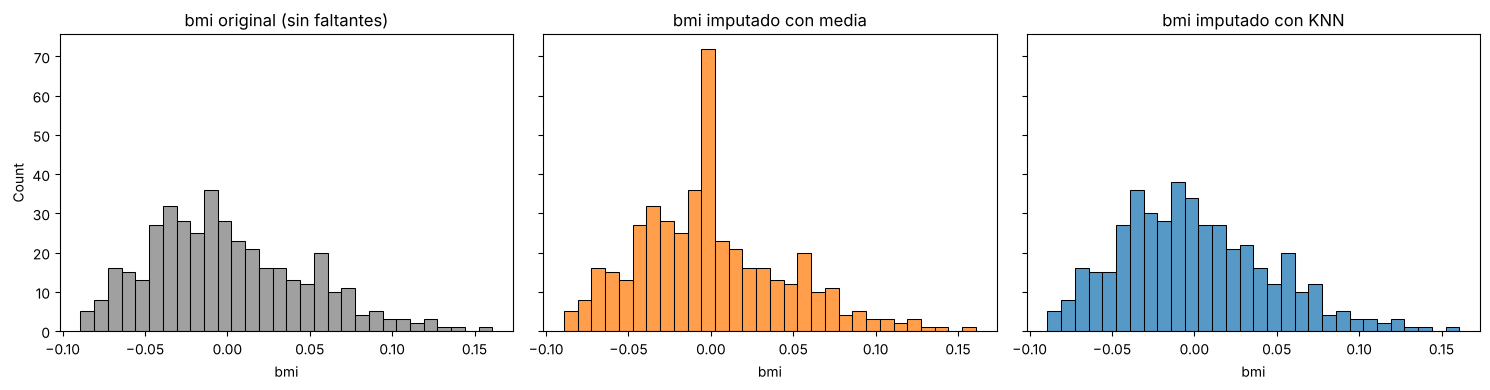

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
sns.histplot(data['bmi'].dropna(), bins=30, ax=axes[0], color='gray')
axes[0].set_title('bmi original (sin faltantes)')
sns.histplot(data_simple['bmi'], bins=30, ax=axes[1], color='tab:orange')
axes[1].set_title('bmi imputado con media')
sns.histplot(data_knn['bmi'], bins=30, ax=axes[2], color='tab:blue')
axes[2].set_title('bmi imputado con KNN')
plt.tight_layout()
plt.show()

**Respuesta:** con la media aparece un pico artificial en el centro de la distribución. Con KNN la forma del histograma se parece mucho más a la original.